# PRCP-1019 - Concrete Strength Prediction

## Project Objective

The objective of this project is to perform complete data analysis on the concrete dataset and build a machine learning model to predict the compressive strength of concrete based on its ingredients and age.

### Project Tasks

1. Perform Exploratory Data Analysis (EDA)
2. Perform data preprocessing
3. Build multiple machine learning regression models
4. Compare model performance
5. Select a suitable model for production
6. Identify challenges and explain the techniques used to solve them

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd

df = pd.read_excel(r"C:\Users\pavan\Downloads\concrete+compressive+strength\Concrete_Data.xls")

df

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075
...,...,...,...,...,...,...,...,...,...
1025,276.4,116.0,90.3,179.6,8.9,870.1,768.3,28,44.284354
1026,322.2,0.0,115.6,196.0,10.4,817.9,813.4,28,31.178794
1027,148.5,139.4,108.6,192.7,6.1,892.4,780.0,28,23.696601
1028,159.1,186.7,0.0,175.6,11.3,989.6,788.9,28,32.768036


In [3]:
import os

print(os.listdir())

['.ipynb_checkpoints', 'PRCP-1018-BikeRental.ipynb', 'PRCP-1019_Concrete_Strength.ipynb', 'Python', 'Statistics.ipynb', 'Untitled.ipynb']


In [4]:
df.head()

,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [5]:
df.shape


(1030, 9)

In [6]:
df.columns

Index(['Cement (component 1)(kg in a m^3 mixture)',
       'Blast Furnace Slag (component 2)(kg in a m^3 mixture)',
       'Fly Ash (component 3)(kg in a m^3 mixture)',
       'Water  (component 4)(kg in a m^3 mixture)',
       'Superplasticizer (component 5)(kg in a m^3 mixture)',
       'Coarse Aggregate  (component 6)(kg in a m^3 mixture)',
       'Fine Aggregate (component 7)(kg in a m^3 mixture)', 'Age (day)',
       'Concrete compressive strength(MPa, megapascals) '],
      dtype='object')

In [7]:
df.columns = [
    "Cement",
    "Blast Furnace Slag",
    "Fly Ash",
    "Water",
    "Superplasticizer",
    "Coarse Aggregate",
    "Fine Aggregate",
    "Age",
    "Concrete Compressive Strength"
]

df.head()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete Compressive Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete Compressive Strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [9]:
df.isnull().sum()

Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete Compressive Strength    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(25)

In [13]:
df = df.drop_duplicates()

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.describe()

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete Compressive Strength
count,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000,1005.000000
mean,278.629055,72.043134,55.535075,182.074378,6.031647,974.376468,772.686617,45.856716,35.250273
std,104.345003,86.170555,64.207448,21.340740,5.919559,77.579534,80.339851,63.734692,16.284808
min,102.000000,0.000000,0.000000,121.750000,0.000000,801.000000,594.000000,1.000000,2.331808
25%,190.680000,0.000000,0.000000,166.610000,0.000000,932.000000,724.300000,7.000000,23.523542
50%,265.000000,20.000000,0.000000,185.700000,6.100000,968.000000,780.000000,28.000000,33.798114
75%,349.000000,142.500000,118.270000,192.940000,10.000000,1031.000000,822.200000,56.000000,44.868340
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.599225


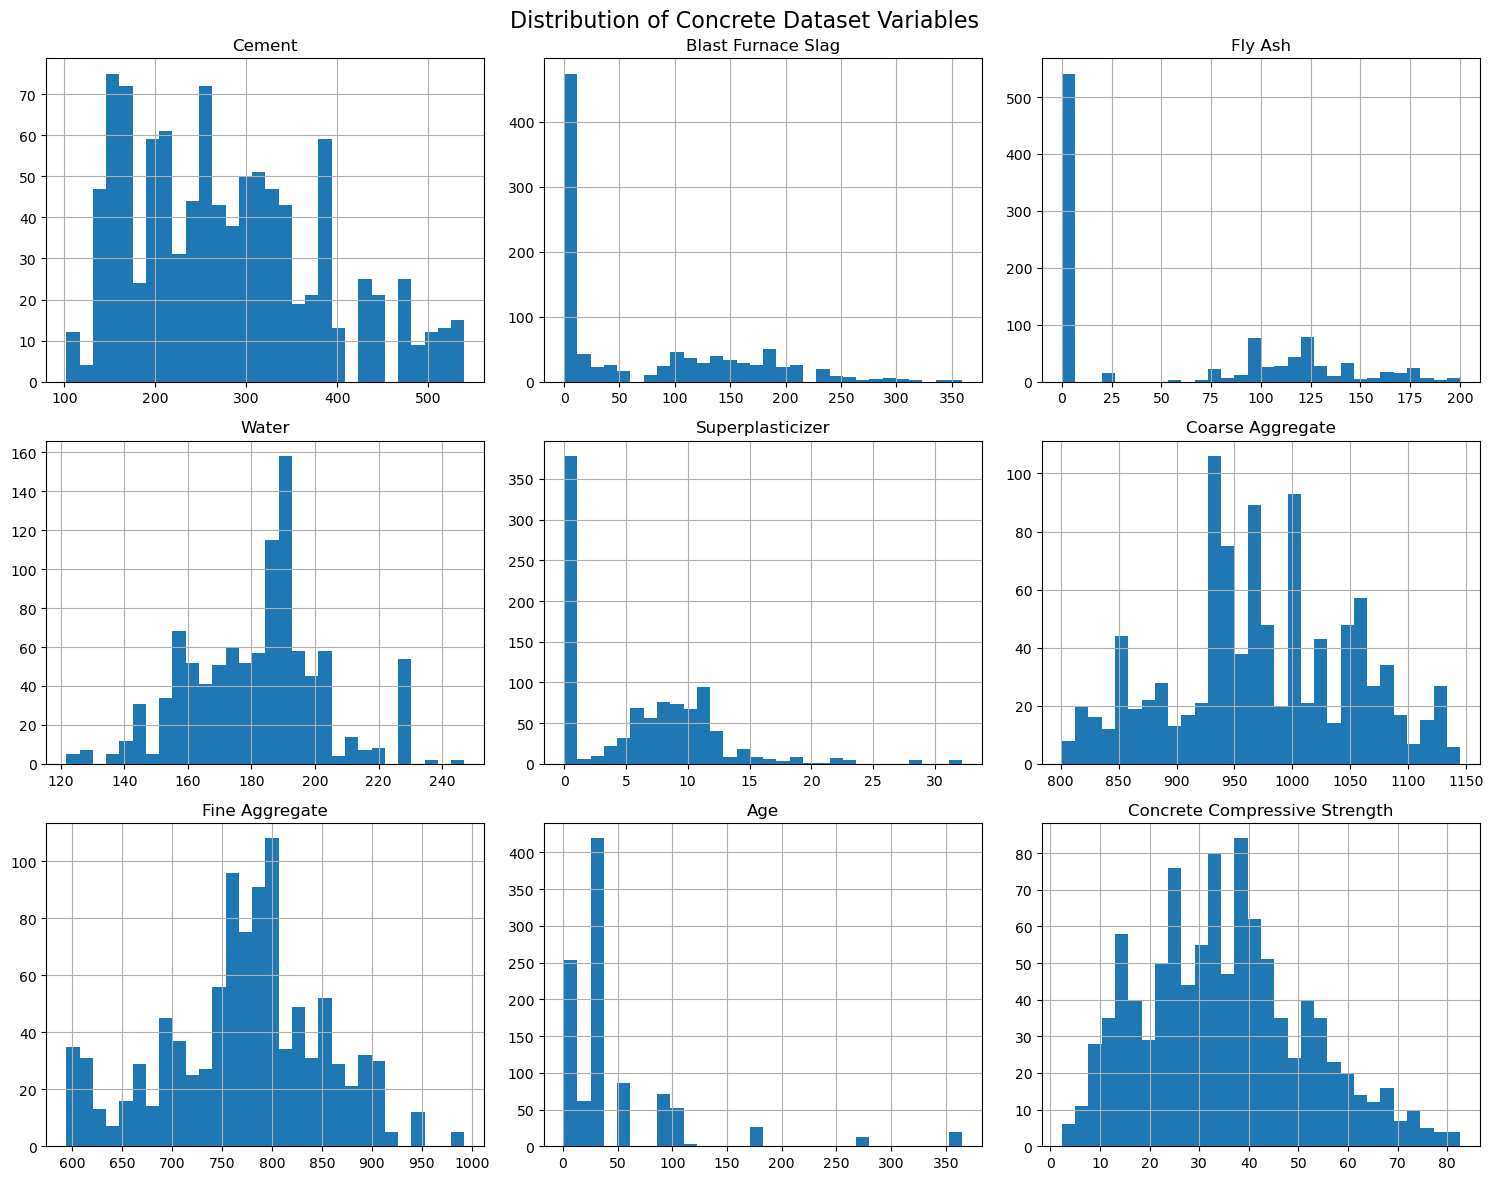

In [16]:
df.hist(figsize=(15, 12), bins=30)

plt.suptitle(
    "Distribution of Concrete Dataset Variables",
    fontsize=16
)

plt.tight_layout()
plt.show()

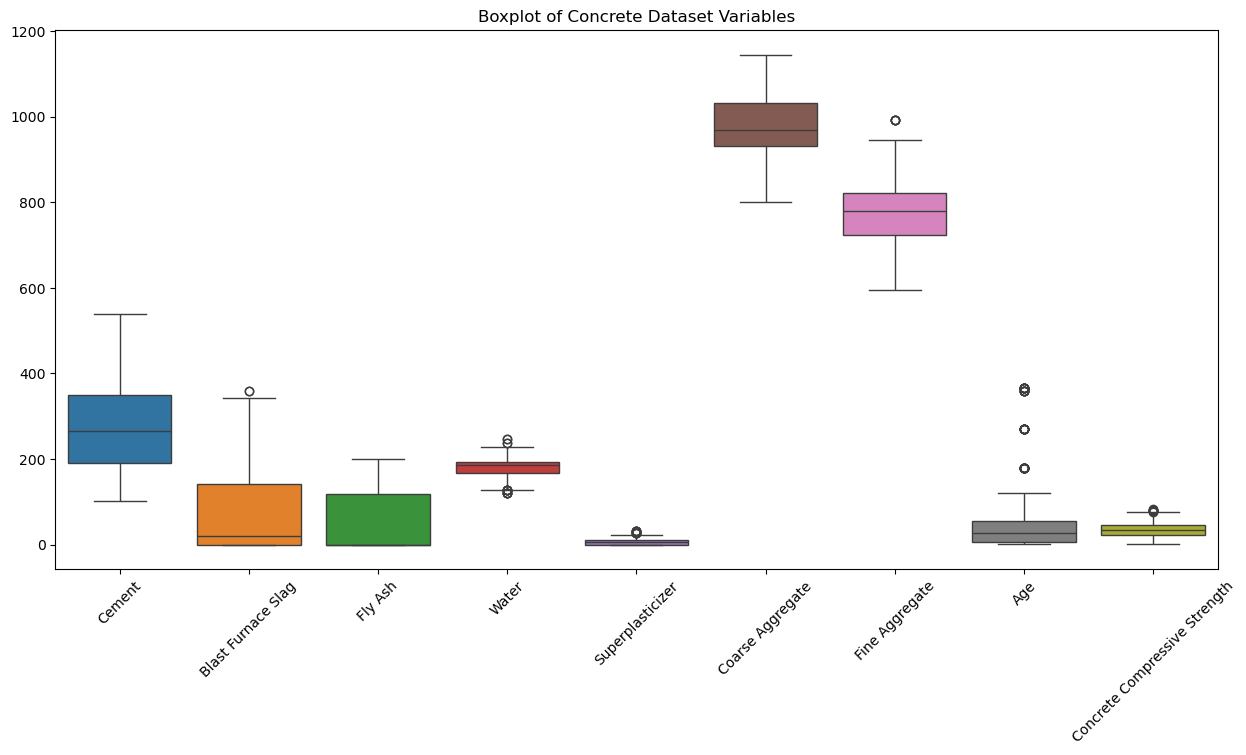

In [17]:
plt.figure(figsize=(15, 7))

sns.boxplot(data=df)

plt.xticks(rotation=45)
plt.title("Boxplot of Concrete Dataset Variables")

plt.show()

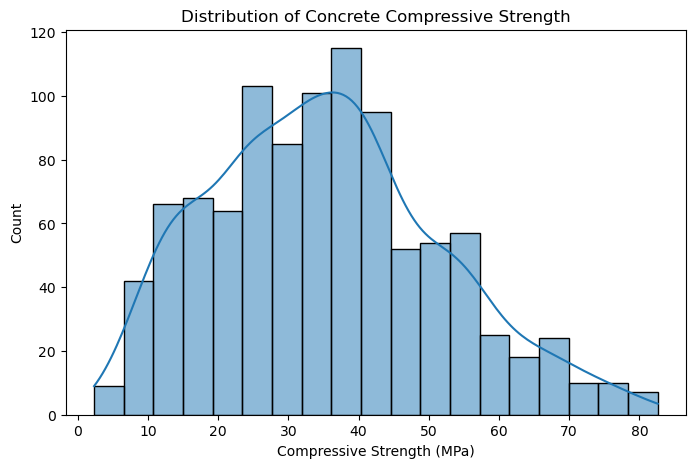

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Concrete Compressive Strength"],
    kde=True
)

plt.title("Distribution of Concrete Compressive Strength")
plt.xlabel("Compressive Strength (MPa)")
plt.show()

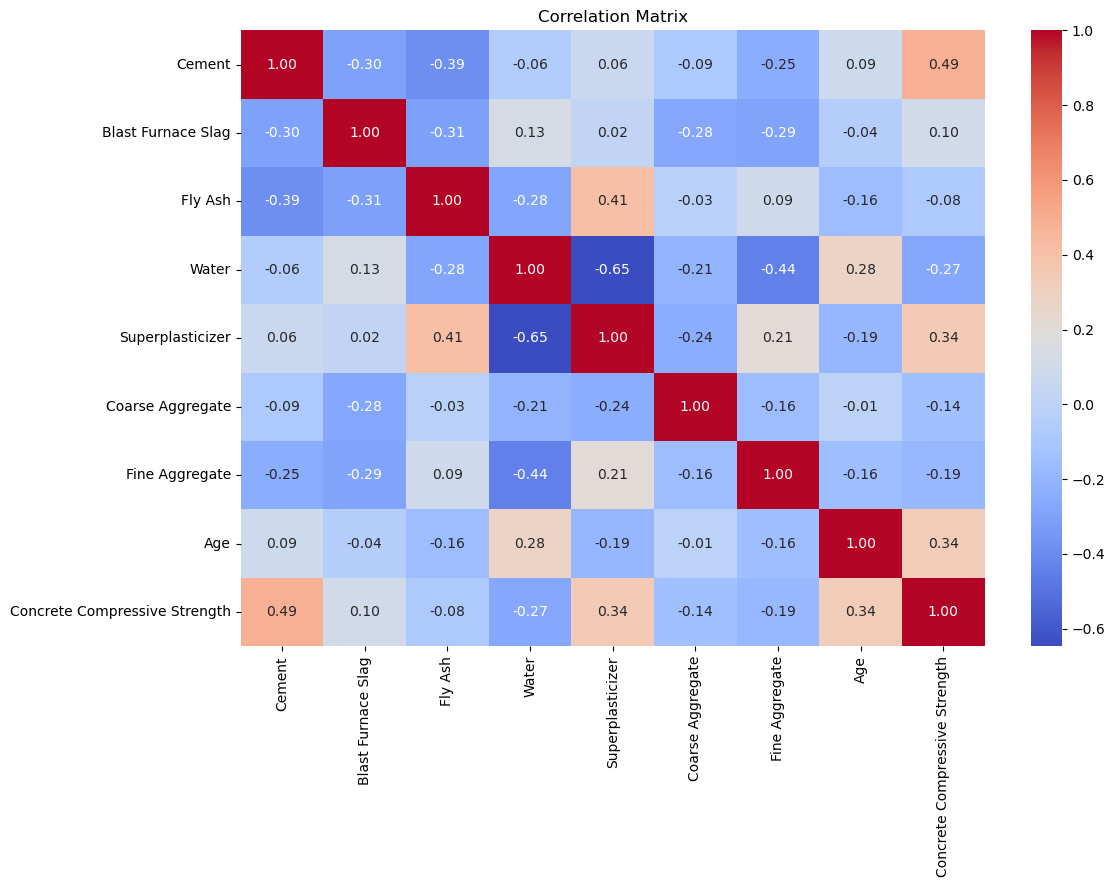

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

In [21]:
X = df.drop(
    "Concrete Compressive Strength",
    axis=1
)

y = df["Concrete Compressive Strength"]

In [22]:
print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1005, 8)
Target shape: (1005,)


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (804, 8)
Testing data: (201, 8)


In [24]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [25]:
linear_model = LinearRegression()

linear_model.fit(
    X_train_scaled,
    y_train
)

linear_pred = linear_model.predict(
    X_test_scaled
)

In [26]:
linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_pred
    )
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)

print("Linear Regression")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R2  :", linear_r2)

Linear Regression
MAE : 8.896027820458997
RMSE: 11.192199885488332
R2  : 0.5801089019953829


In [27]:
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(
    X_train_scaled,
    y_train
)

ridge_pred = ridge_model.predict(
    X_test_scaled
)

ridge_mae = mean_absolute_error(
    y_test,
    ridge_pred
)

ridge_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        ridge_pred
    )
)

ridge_r2 = r2_score(
    y_test,
    ridge_pred
)

print("Ridge Regression")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2  :", ridge_r2)

Ridge Regression
MAE : 8.898276954274522
RMSE: 11.19423560599039
R2  : 0.5799561422765539


In [28]:
dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(
    X_train,
    y_train
)

dt_pred = dt_model.predict(
    X_test
)

dt_mae = mean_absolute_error(
    y_test,
    dt_pred
)

dt_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        dt_pred
    )
)

dt_r2 = r2_score(
    y_test,
    dt_pred
)

print("Decision Tree")
print("MAE :", dt_mae)
print("RMSE:", dt_rmse)
print("R2  :", dt_r2)

Decision Tree
MAE : 3.8733713009986532
RMSE: 6.4745602273738125
R2  : 0.8594838305949289


In [29]:
rf_model = RandomForestRegressor(
    n_estimators=500,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("Random Forest")
print("MAE :", rf_mae)
print("RMSE:", rf_rmse)
print("R2  :", rf_r2)

Random Forest
MAE : 3.4668576847447024
RMSE: 5.125583088386776
R2  : 0.9119372369070421


In [30]:
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.03,
    max_depth=3,
    random_state=42
)

gb_model.fit(
    X_train,
    y_train
)

gb_pred = gb_model.predict(
    X_test
)

gb_mae = mean_absolute_error(
    y_test,
    gb_pred
)

gb_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        gb_pred
    )
)

gb_r2 = r2_score(
    y_test,
    gb_pred
)

print("Gradient Boosting")
print("MAE :", gb_mae)
print("RMSE:", gb_rmse)
print("R2  :", gb_r2)

Gradient Boosting
MAE : 4.108084193825279
RMSE: 5.5742162569161815
R2  : 0.8958466174431944


In [31]:
et_model = ExtraTreesRegressor(
    n_estimators=500,
    random_state=42
)

et_model.fit(
    X_train,
    y_train
)

et_pred = et_model.predict(
    X_test
)

et_mae = mean_absolute_error(
    y_test,
    et_pred
)

et_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        et_pred
    )
)

et_r2 = r2_score(
    y_test,
    et_pred
)

print("Extra Trees")
print("MAE :", et_mae)
print("RMSE:", et_rmse)
print("R2  :", et_r2)

Extra Trees
MAE : 2.9228723508165952
RMSE: 4.7760875737922674
R2  : 0.9235371793805776


In [32]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Extra Trees"
    ],
    
    "MAE": [
        linear_mae,
        ridge_mae,
        dt_mae,
        rf_mae,
        gb_mae,
        et_mae
    ],
    
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        dt_rmse,
        rf_rmse,
        gb_rmse,
        et_rmse
    ],
    
    "R2": [
        linear_r2,
        ridge_r2,
        dt_r2,
        rf_r2,
        gb_r2,
        et_r2
    ]
})

results.sort_values(
    "RMSE"
)

,Model,MAE,RMSE,R2
5,Extra Trees,2.922872,4.776088,0.923537
3,Random Forest,3.466858,5.125583,0.911937
4,Gradient Boosting,4.108084,5.574216,0.895847
2,Decision Tree,3.873371,6.474560,0.859484
0,Linear Regression,8.896028,11.192200,0.580109
1,Ridge Regression,8.898277,11.194236,0.579956


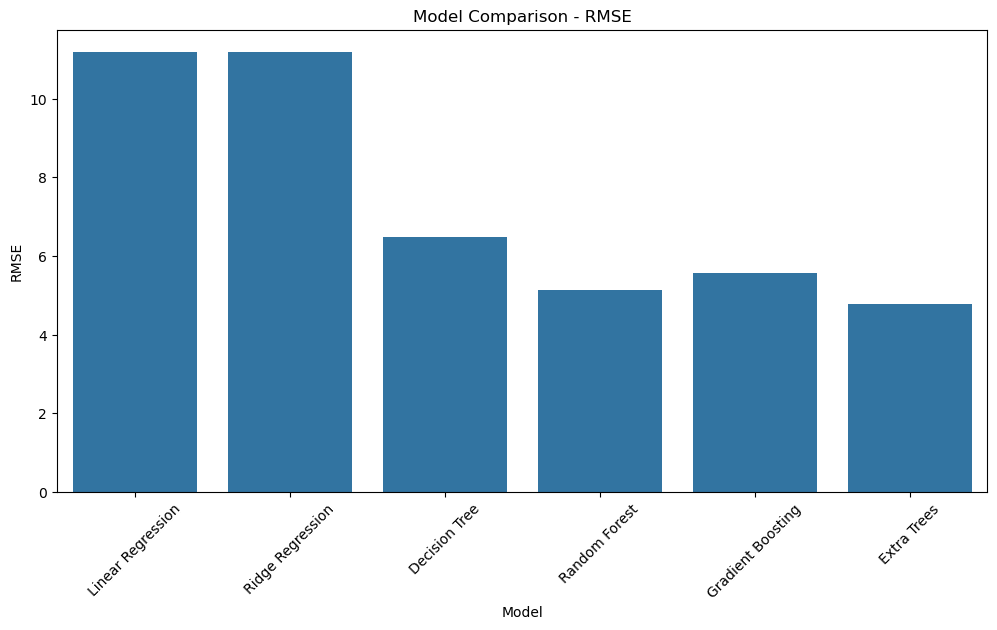

In [33]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE"
)

plt.xticks(rotation=45)
plt.title("Model Comparison - RMSE")

plt.show()

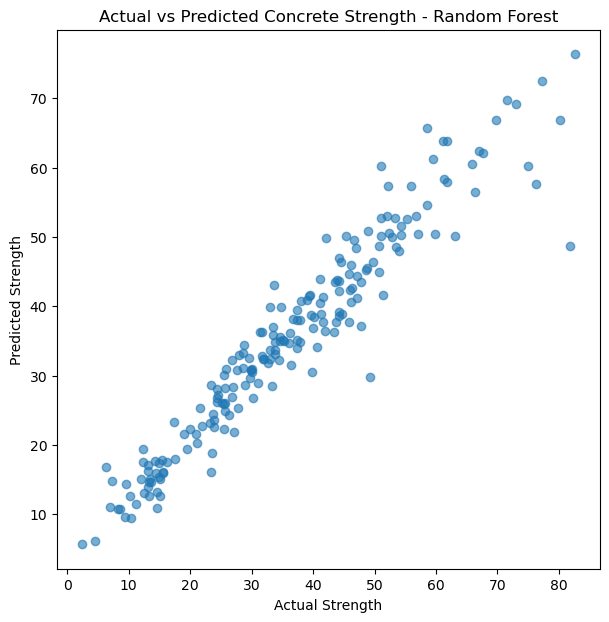

In [34]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.6
)

plt.xlabel("Actual Strength")
plt.ylabel("Predicted Strength")

plt.title(
    "Actual vs Predicted Concrete Strength - Random Forest"
)

plt.show()

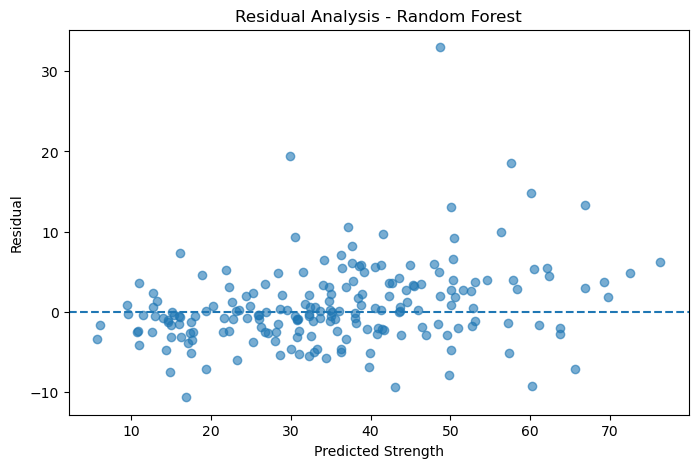

In [35]:
residuals = y_test - rf_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    rf_pred,
    residuals,
    alpha=0.6
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Strength")
plt.ylabel("Residual")

plt.title(
    "Residual Analysis - Random Forest"
)

plt.show()

In [36]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X.columns
).sort_values(
    ascending=False
)

print(importance)

Age                   0.351589
Cement                0.311102
Water                 0.090002
Superplasticizer      0.084264
Blast Furnace Slag    0.077130
Fine Aggregate        0.043777
Coarse Aggregate      0.025861
Fly Ash               0.016275
dtype: float64


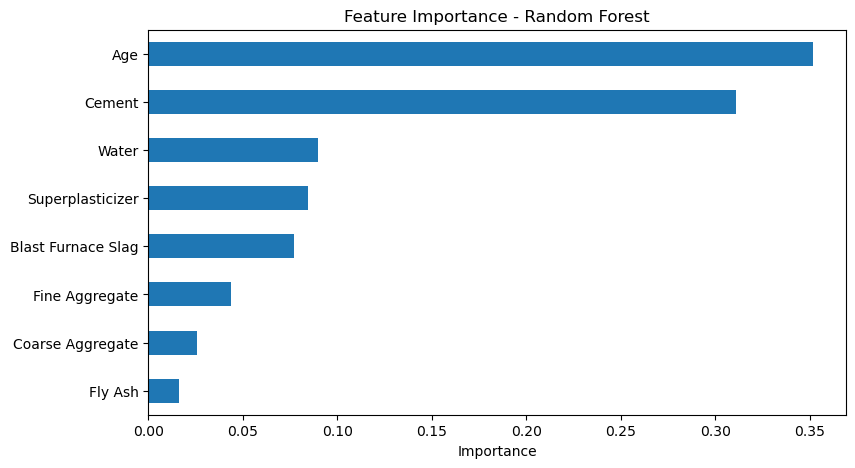

In [37]:
plt.figure(figsize=(9, 5))

importance.sort_values().plot(
    kind="barh"
)

plt.title(
    "Feature Importance - Random Forest"
)

plt.xlabel("Importance")

plt.show()

# Final Conclusion

In this project, exploratory data analysis was performed on the concrete dataset to understand the distributions, relationships, correlations, and possible outliers.

The dataset contains eight input variables related to the composition and age of the concrete mix, while concrete compressive strength is the target variable.

Multiple regression algorithms were implemented, including Linear Regression, Ridge Regression, Decision Tree, Random Forest, Gradient Boosting, and Extra Trees.

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² score.

The model with the lowest RMSE and strong overall validation performance was selected as the production candidate. The actual model name and performance values should be reported from the model comparison table generated in this notebook.

The model can be used to estimate concrete compressive strength for a new mix based on its constituent quantities and age. However, predictions should be additionally validated with appropriate laboratory testing and engineering requirements before being used for real construction decisions.